[*********************100%***********************]  10 of 10 completed

正在从 yfinance 下载股票历史数据...
数据加载完成！有效公共交易日天数: 751

【各股票日收益率的期望、方差与波动率】
                       Sector  Mean (mu)  Variance (sigma^2)  Volatility (sigma)
AAPL         Information Tech   0.000727            0.000284            0.016849
JPM                Financials   0.001279            0.000210            0.014508
JNJ                Healthcare   0.000788            0.000127            0.011281
AMZN   Consumer Discretionary   0.000877            0.000410            0.020253
PG           Consumer Staples   0.000011            0.000127            0.011274
XOM                    Energy   0.000589            0.000218            0.014761
GOOGL  Communication Services   0.001257            0.000369            0.019216
CAT               Industrials   0.001451            0.000414            0.020338
NEE                 Utilities   0.000390            0.000296            0.017209
LIN                 Materials   0.000364            0.000127            0.011276

【十只股票日收益率的相关系数矩阵】
Ticker     AAPL      J

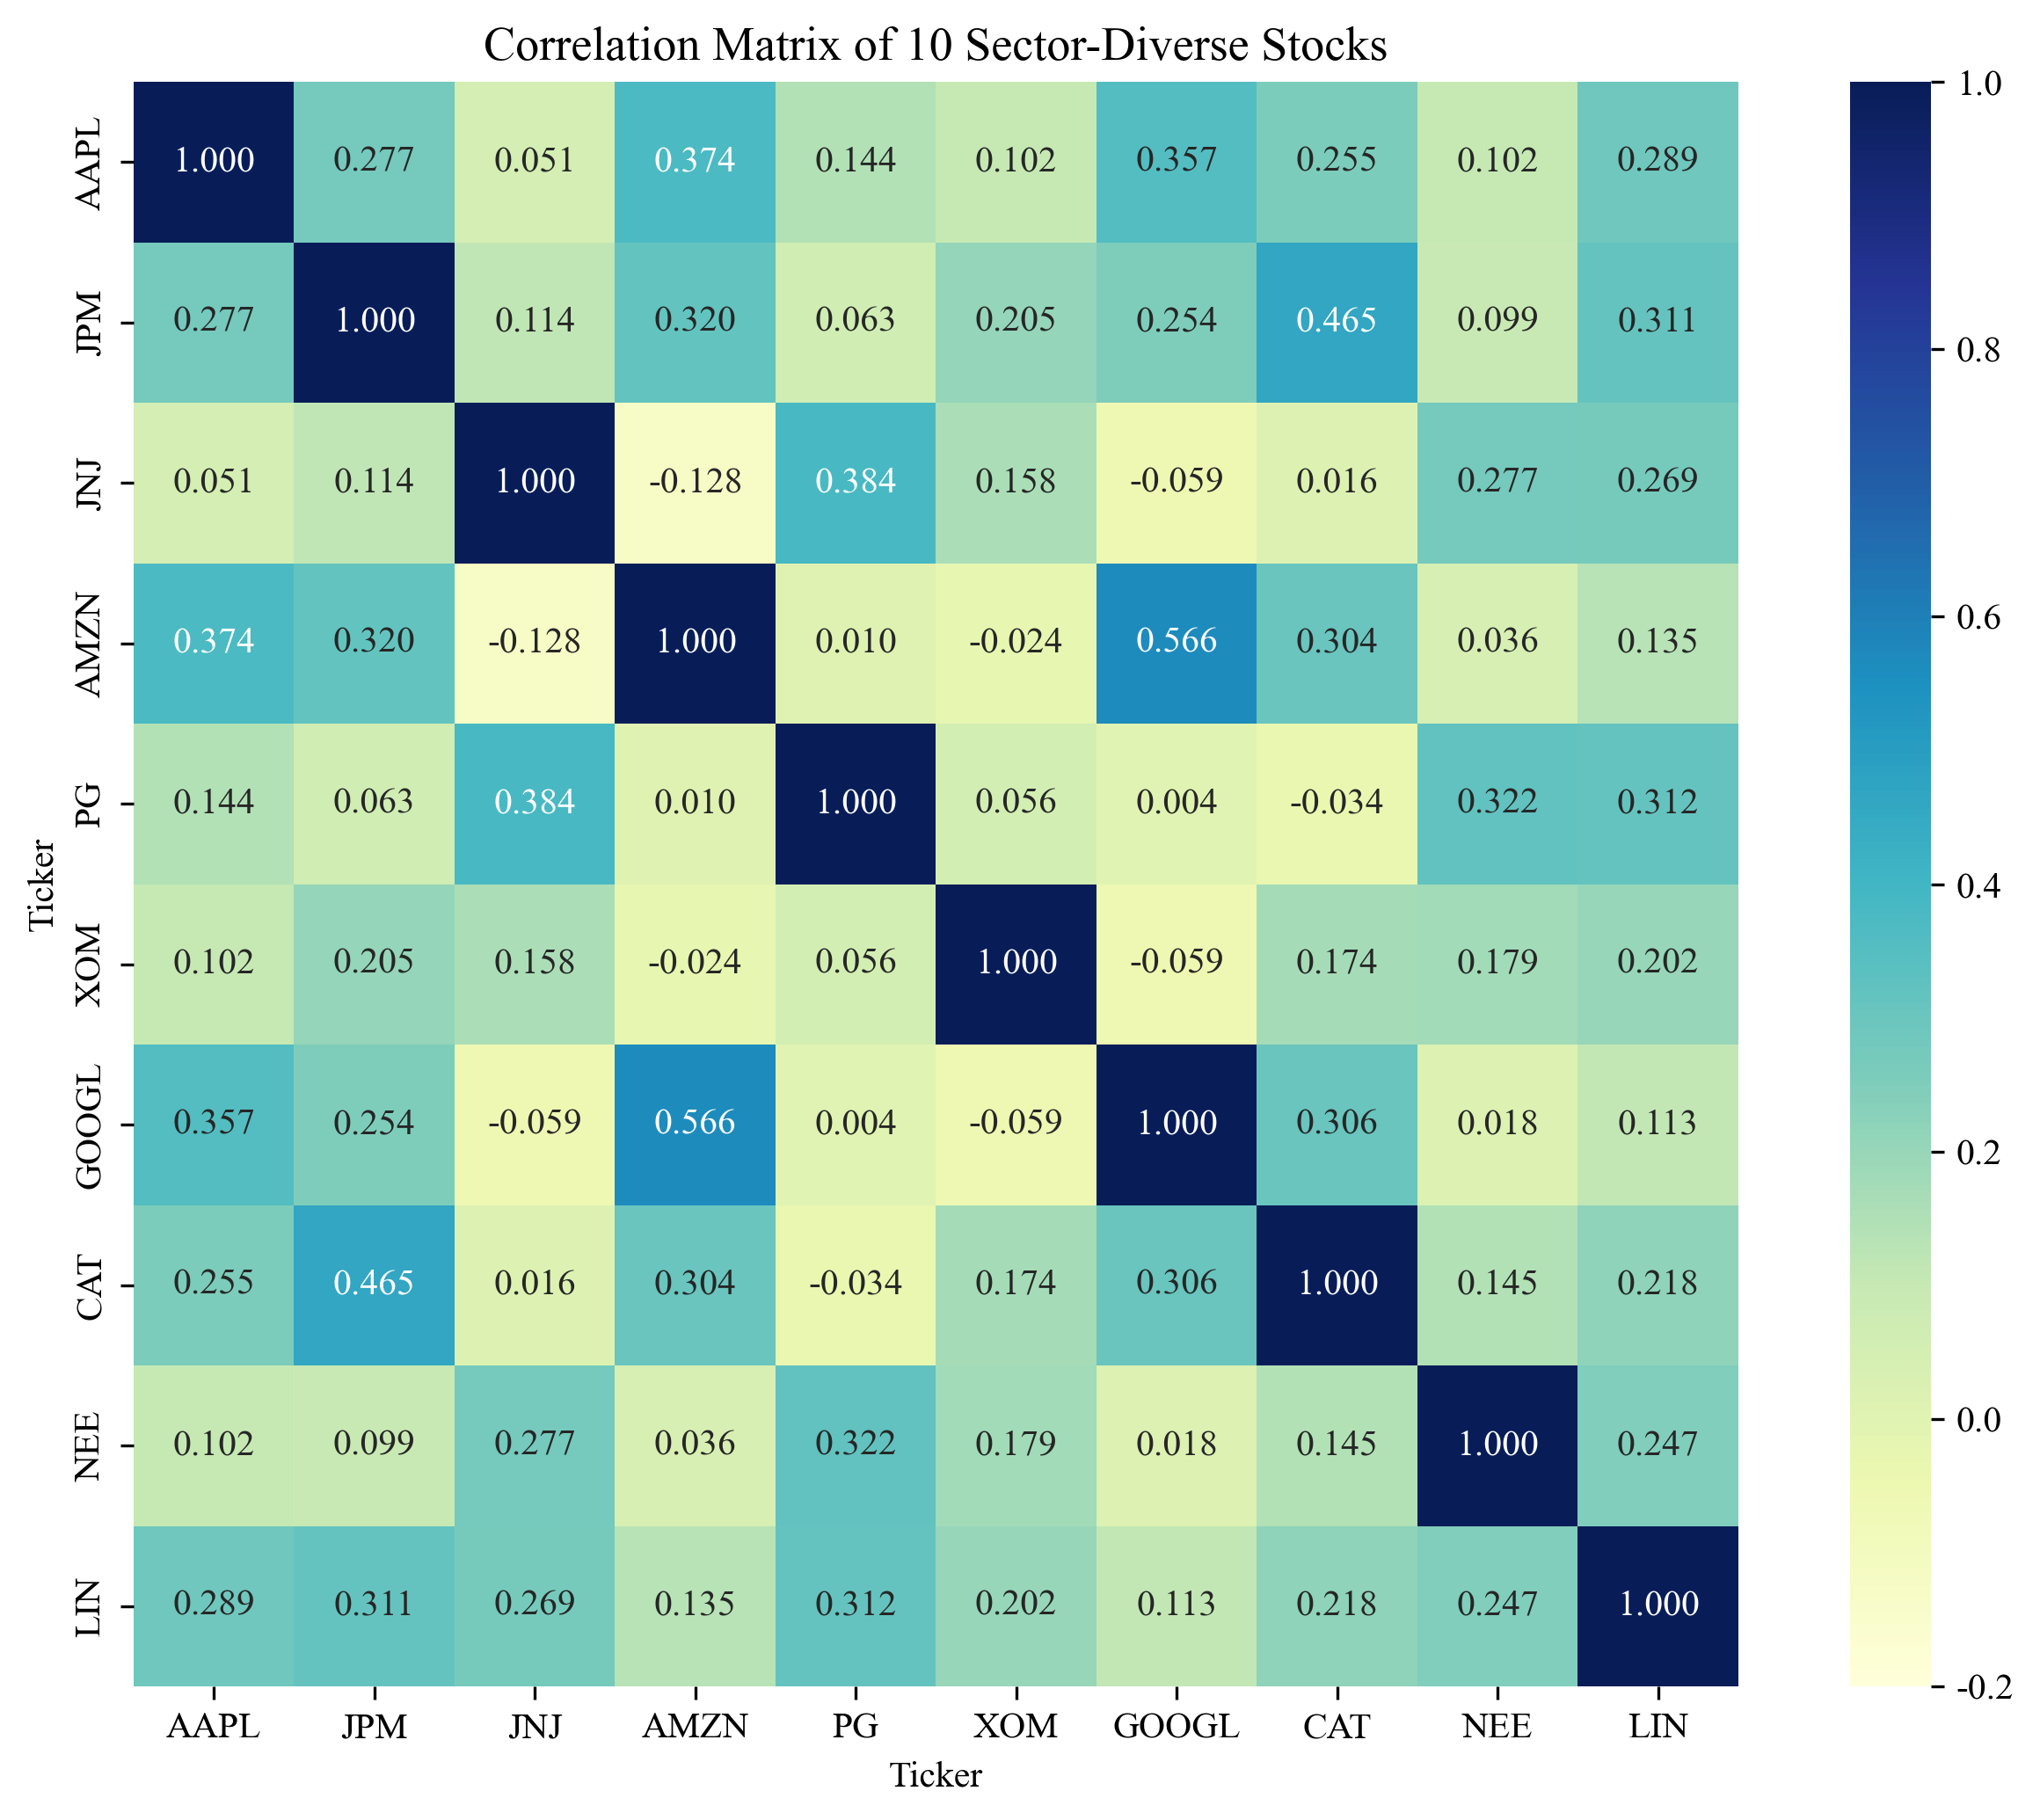


【投资组合风险分解报告 (总资产 W = $1,000,000.00, 置信度 95%)】
                       Sector  Weight (w_i)     Beta  Marginal VaR  Component VaR ($)  Risk Share (%)
AAPL         Information Tech      0.100000 1.250912      0.016750        1674.998786       12.509117
JPM                Financials      0.100000 1.098936      0.014715        1471.500264       10.989362
JNJ                Healthcare      0.100000 0.423200      0.005667         566.673918        4.231997
AMZN   Consumer Discretionary      0.100000 1.489003      0.019938        1993.807852       14.890026
PG           Consumer Staples      0.100000 0.484058      0.006482         648.164660        4.840581
XOM                    Energy      0.100000 0.649127      0.008692         869.195077        6.491266
GOOGL  Communication Services      0.100000 1.353822      0.018128        1812.797635       13.538217
CAT               Industrials      0.100000 1.556568      0.020843        2084.279144       15.565677
NEE                 Utilities      

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yfinance as yf

# 设置显示格式与字体
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: "%.6f" % x)
plt.rcParams["font.sans-serif"] = ["Times New Roman"]
plt.rcParams["axes.unicode_minus"] = False

# =====================================================================
# 1. 选取 10 只分属不同行业的代表性股票并下载至少 2 年历史数据
# =====================================================================
tickers_dict = {
    "AAPL": "Information Tech",
    "JPM": "Financials",
    "JNJ": "Healthcare",
    "AMZN": "Consumer Discretionary",
    "PG": "Consumer Staples",
    "XOM": "Energy",
    "GOOGL": "Communication Services",
    "CAT": "Industrials",
    "NEE": "Utilities",
    "LIN": "Materials",
}

stock_list = list(tickers_dict.keys())
tickers_str = " ".join(stock_list)

# 下载 3 年完整数据 (2023-08-31 到 2026-08-31)
print("正在从 yfinance 下载股票历史数据...")
raw_data = yf.download(
    tickers_str, start="2023-08-31", end="2026-08-31", auto_adjust=True
)

# 提取收盘价，清洗并对齐公共交易日
if "Close" in raw_data.columns.levels[0]:
    close_prices = raw_data["Close"][stock_list].dropna()
else:
    close_prices = raw_data[stock_list].dropna()

print(f"数据加载完成！有效公共交易日天数: {len(close_prices)}")

# =====================================================================
# 2. 计算日对数收益率、期望、方差与相关系数矩阵
# =====================================================================
# 计算日对数收益率 R_t = ln(S_t) - ln(S_{t-1})
returns_df = np.log(close_prices / close_prices.shift(1)).dropna()

# (1) 期望向量 mu 与 方差向量 sigma^2
mu_hat = returns_df.mean()  # 日期望收益率
var_hat = returns_df.var()  # 日方差
std_hat = returns_df.std()  # 日波动率(标准差)

# (2) 协方差矩阵 Sigma 与 相关系数矩阵 Corr
Sigma_matrix = returns_df.cov()
Corr_matrix = returns_df.corr()

# 整理各资产统计参数表
asset_stats = pd.DataFrame(
    {
        "Sector": [tickers_dict[t] for t in stock_list],
        "Mean (mu)": mu_hat,
        "Variance (sigma^2)": var_hat,
        "Volatility (sigma)": std_hat,
    },
    index=stock_list,
)

print("\n" + "=" * 70)
print("【各股票日收益率的期望、方差与波动率】")
print("=" * 70)
print(asset_stats)

print("\n" + "=" * 70)
print("【十只股票日收益率的相关系数矩阵】")
print("=" * 70)
print(Corr_matrix.round(4))

# 绘制相关系数热力图
plt.figure(figsize=(9, 7), dpi=300)
sns.heatmap(
    Corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=-0.2,
    vmax=1.0,
    square=True,
)
plt.title("Correlation Matrix of 10 Sector-Diverse Stocks", fontsize=13)
plt.tight_layout()
plt.show()

# =====================================================================
# 3. 设计投资组合并计算 VaR、边际 VaR 和成分 VaR
# =====================================================================
# 设计投资组合: 假设总资产 W = 1,000,000 美元
W_total = 1_000_000.0

# 权重设计 (此处采用等权重组合，也可以自定义非等权重向量)
weights = np.array([0.10] * 10)  # 各占 10%
# 若自定义权重示例: weights = np.array([0.15, 0.15, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.05, 0.05])

# 各资产投资金额向量 x_i
x_vec = W_total * weights

# 置信度 alpha = 0.95
alpha = 0.95
z_alpha = 1.6448536  # Phi^{-1}(0.95)

# 组合方差与组合波动率计算
# sigma_p^2 = w' * Sigma * w
Sigma_val = Sigma_matrix.values
port_variance = float(np.dot(weights.T, np.dot(Sigma_val, weights)))
port_sigma = np.sqrt(port_variance)

# 组合总体 VaR (美元金额)
# VaR = Phi^{-1}(alpha) * W * sigma_p
portfolio_VaR = z_alpha * W_total * port_sigma

# 协方差项 Cov(R_i, R_p) = (Sigma * w)_i
cov_i_p = np.dot(Sigma_val, weights)

# 贝塔系数 beta_i = Cov(R_i, R_p) / sigma_p^2
betas = cov_i_p / port_variance

# (1) 边际 VaR (Marginal VaR): \Delta VaR_i = (VaR / W) * beta_i
marginal_VaR = (portfolio_VaR / W_total) * betas

# (2) 成分 VaR (Component VaR): CVaR_i = x_i * \Delta VaR_i = VaR * w_i * beta_i
component_VaR = x_vec * marginal_VaR

# (3) 风险贡献率: %CVaR_i = CVaR_i / VaR = w_i * beta_i
pct_contribution = component_VaR / portfolio_VaR

# 资产单独的独立 VaR (未分散 VaR)
individual_VaR = z_alpha * x_vec * std_hat.values

# 汇总输出结果表
risk_analysis_df = pd.DataFrame(
    {
        "Sector": [tickers_dict[t] for t in stock_list],
        "Weight (w_i)": weights,
        "Position ($)": x_vec,
        "Beta": betas,
        "Marginal VaR": marginal_VaR,
        "Component VaR ($)": component_VaR,
        "Risk Share (%)": pct_contribution * 100,
        "Individual VaR ($)": individual_VaR,
    },
    index=stock_list,
)

print("\n" + "=" * 90)
print(f"【投资组合风险分解报告 (总资产 W = ${W_total:,.2f}, 置信度 95%)】")
print("=" * 90)
print(
    risk_analysis_df[
        [
            "Sector",
            "Weight (w_i)",
            "Beta",
            "Marginal VaR",
            "Component VaR ($)",
            "Risk Share (%)",
        ]
    ]
)

print("\n" + "-" * 60)
print(f"组合日收益率标准差 (sigma_p) : {port_sigma:.6f}")
print(f"分散化后的组合总 VaR_0.95   : ${portfolio_VaR:,.2f}")
print(f"未分散化各资产独立 VaR 之和  : ${individual_VaR.sum():,.2f}")
print(f"成分 VaR 欧拉求和验证 Sum(CVaR): ${component_VaR.sum():,.2f}")
print(f"风险分散化效应节约金额      : ${individual_VaR.sum() - portfolio_VaR:,.2f}")
print("-" * 60)